# Speckle reconstruction with PyTorch

Compare three simple workflows on the same data:

1. **AD:** optimize the phase with Adam.
2. **Projections (RAAR -> ER):** use RAAR, then finish with ER.
3. **Projections + AD:** refine the RAAR-ER result with Adam.

All three begin with the same random phase. The final figures show the recovered
phases and their errors beside the reference. The reference phase is used only
for evaluation, never for reconstruction.

Run from `notebooks/` or the repository root after installing the package with
`python -m pip install -e .`.

In [1]:
%matplotlib inline

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import torch

root = Path.cwd()

if not (root / "speckleret").is_dir():
    root = root.parent

sys.path.insert(0, str(root))

from speckleret.plots import complex_to_hsv
from speckleret.torch import initializers, metrics, optimization, retrieval, supports, transforms


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if device.type == "cpu":
    torch.set_num_threads(min(4, torch.get_num_threads()))

print("Device:", device)

Device: cuda


## Prepare the data

The supplied array is a complex field. Add batch and channel axes to obtain
`[N, C, H, W]`, then pad the field and simulate the near and far measurements.
The reconstruction uses **amplitudes**, the square roots of camera intensities.
Keep the same relative calibration between planes.

In [2]:
field = np.load(root / "imports" / "grin_speckle_example.npy")

reference = torch.as_tensor(field, dtype=torch.complex64, device=device)
reference = reference[None, None]
reference = transforms.normalize_field(reference, norm_type="max")

height, width = reference.shape[-2:]
original_size = (height, width)

reference = transforms.pad_to_size(
    reference,
    (height + height // 2, width + width // 2),
)

near = reference.abs()
far = transforms.fourier_transform(reference).abs()

print("Shape [N, C, H, W]:", tuple(reference.shape))

Shape [N, C, H, W]: (1, 1, 384, 384)


## Choose the support and starting phase

The support marks where the object can be nonzero. Here the noiseless simulated
near measurement gives the exact footprint. For camera data, replace this with
a conservative measured or geometric support.

Use one shared random starting field so the comparison is easy to interpret.

In [3]:
support = near > 0

generator = torch.Generator(device=device).manual_seed(7)

start = initializers.random_phases(near, generator=generator)
start = transforms.apply_support(start, support)

raar_steps = 200
er_steps = 100
ad_steps = 200
learning_rate = 0.1

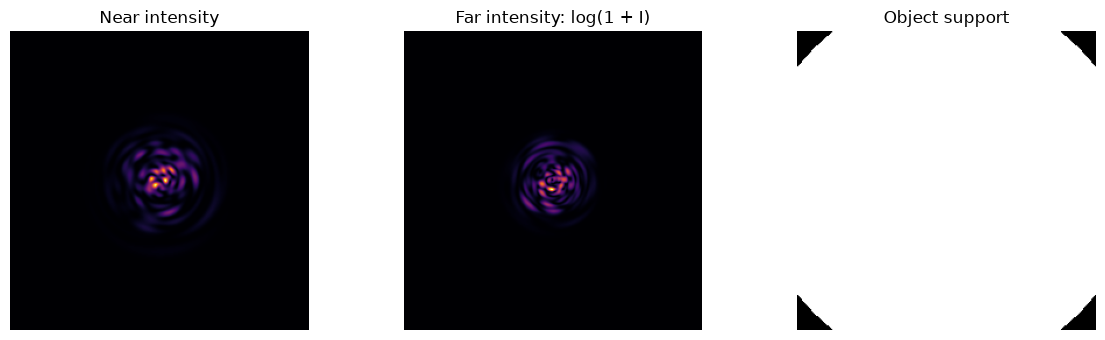

In [4]:
def as_image(tensor):
    cropped = transforms.crop_to_size(tensor, original_size)
    return cropped.detach().cpu().squeeze().numpy()


fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))

axes[0].imshow(as_image(near.square()), cmap="inferno")
axes[0].set_title("Near intensity")

axes[1].imshow(as_image(torch.log1p(far.square())), cmap="inferno")
axes[1].set_title("Far intensity: log(1 + I)")

axes[2].imshow(as_image(support), cmap="gray")
axes[2].set_title("Object support")

for ax in axes:
    ax.set_axis_off()

plt.tight_layout()
plt.show()

## A few support choices

A support is a boolean object-plane mask. Here are three alternatives to the
exact simulated footprint used above:

- **Disk:** a simple geometric boundary, independent of measured intensity.
- **Threshold:** keeps pixels above a fraction of peak **intensity**.
- **Shrinkwrap:** smooths intensity before thresholding for a less speckled mask.

These examples are for inspection; the main comparison keeps `support = near > 0`.
An overly tight mask removes signal. In camera data, inspect the boundary before
using it. `threshold=0.01` means 1% of peak intensity, not amplitude.

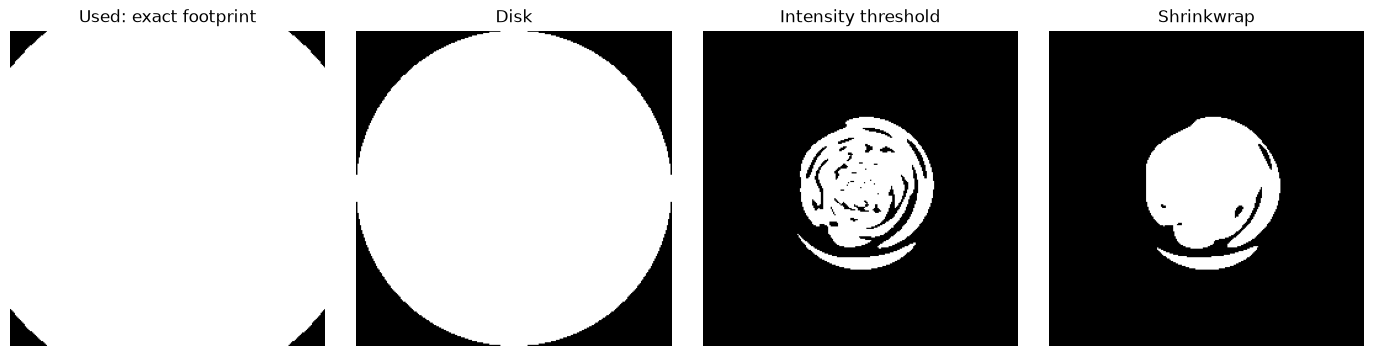

In [5]:
support_examples = {
    "Used: exact footprint": support,
    "Disk": supports.disk_support(near, radius=min(original_size) / 2),
    "Intensity threshold": supports.threshold_support(near, threshold=0.01),
    "Shrinkwrap": supports.shrinkwrap(near, filter_sigma=2., threshold=0.01),
}

fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))

for ax, (name, mask) in zip(axes, support_examples.items()):
    ax.imshow(as_image(mask), cmap="gray", vmin=0, vmax=1)
    ax.set_title(name)
    ax.set_axis_off()

plt.tight_layout()
plt.show()

# To use another mask, assign it in the starting-phase cell and rerun below.
# Example: support = supports.disk_support(near, radius=min(original_size) / 2)

## 1. AD only

Adam learns the phase while keeping the supported near amplitude fixed.
The objective is normalized far amplitude MSE. `return_best=True` includes the
starting field when selecting the best result.

In [6]:
ad_field, ad_history = optimization.reconstruct(
    (near, far),
    support=support,
    init=start,
    optimizer_class=torch.optim.Adam,
    optimizer_kwargs={"lr": learning_rate},
    max_iter=ad_steps,
    metric_every=10,
    return_best=True,
)

## 2. Projections: RAAR followed by ER

Use the established sequence: **200 RAAR updates with beta = 0.9, then 100 ER
updates**. Pass the final RAAR state directly into ER. RAAR explores with
relaxed reflections; ER finishes by enforcing the measured amplitudes and support.

Keep `return_best=False` in the RAAR stage: selecting an earlier raw state by
Fourier residual can interrupt its trajectory before ER. The ER output is the
projection result we display, score, and refine. Neither stage uses the reference
phase for selection.

In [7]:
raar_field, raar_history = retrieval.run(
    (near, far),
    support=support,
    init=start,
    algorithm=retrieval.RAAR,
    algorithm_kwargs={"beta": 0.9},
    max_iter=raar_steps,
    metric_every=10,
    return_best=False,
)

projection_field, er_history = retrieval.run(
    (near, far),
    support=support,
    init=raar_field,
    algorithm=retrieval.ER,
    max_iter=er_steps,
    metric_every=10,
    return_best=False,
)

## 3. Projections followed by AD

Start Adam from **the projection field above**, with the same learning rate and
AD budget as the first workflow. This makes the refinement step explicit.
The combined workflow uses both the RAAR-ER and AD budgets, so it does more
work than either method alone. If RAAR-ER already converges, AD has little to
improve; the returned best objective includes its initialization.

In [8]:
hybrid_field, hybrid_history = optimization.reconstruct(
    (near, far),
    support=support,
    init=projection_field,
    optimizer_class=torch.optim.Adam,
    optimizer_kwargs={"lr": learning_rate},
    max_iter=ad_steps,
    metric_every=10,
    return_best=True,
)

## Compare the recovered phases

A global phase offset cannot be determined from these measurements. Align that
single offset to the reference **for display only**. All phase panels use the
same cyclic color scale from -pi to pi. Hide weak pixels where phase is unreliable;
this display mask is separate from the reconstruction support.

All image panels are center-cropped to the original 256 x 256 array size.
Reconstruction and quantitative metrics still use the full padded grid.

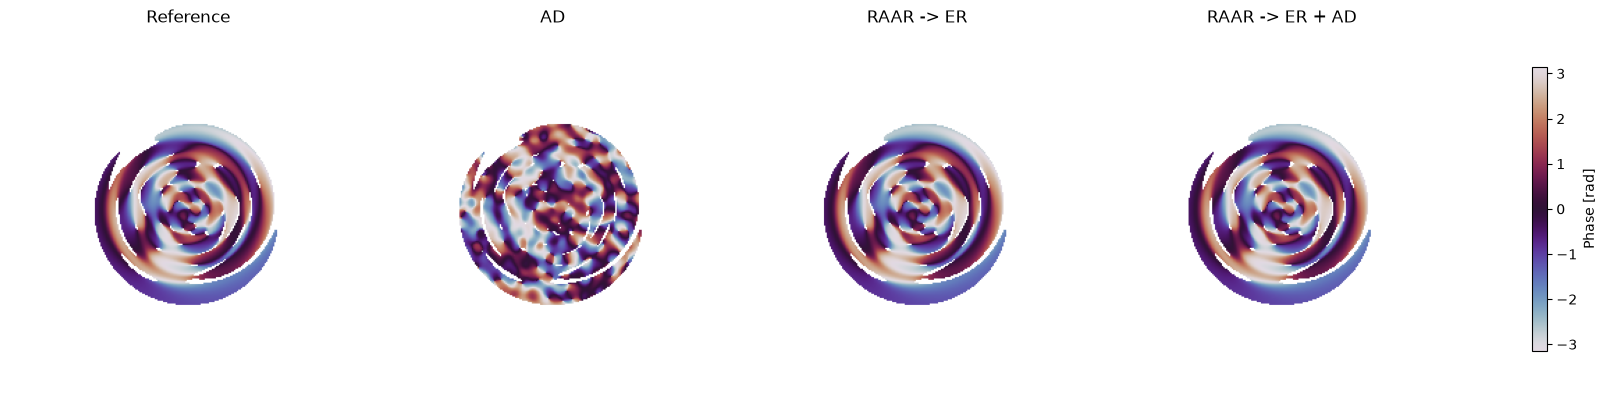

In [9]:
results = {
    "AD": ad_field,
    "RAAR -> ER": projection_field,
    "RAAR -> ER + AD": hybrid_field,
}

phase_mask = support & (near > 0.05 * near.amax())


def align_global_phase(estimate):
    overlap = (reference.conj() * estimate * support).sum()
    return estimate * torch.exp(-1j * overlap.angle())


def visible_phase(field):
    phase = torch.where(phase_mask, field.angle(), torch.nan)
    return as_image(phase)


aligned_results = {
    name: align_global_phase(estimate)
    for name, estimate in results.items()
}

phase_panels = {"Reference": reference, **aligned_results}

fig, axes = plt.subplots(1, 4, figsize=(16, 4), constrained_layout=True)

for ax, (name, estimate) in zip(axes, phase_panels.items()):
    phase_plot = ax.imshow(
        visible_phase(estimate),
        cmap="twilight",
        vmin=-np.pi,
        vmax=np.pi,
    )

    ax.set_title(name)
    ax.set_axis_off()

fig.colorbar(phase_plot, ax=axes.tolist(), label="Phase [rad]", shrink=0.75)
plt.show()

## Amplitudes and colored complex fields

Compare the reference and each reconstruction in the original image size.
Amplitudes use **grayscale**. Complex fields use the existing
`speckleret.plots.complex_to_hsv` convention from the other notebooks:
**hue encodes phase, brightness encodes amplitude**.

Each plane shares one amplitude scale across all four methods. The near-plane
amplitudes match by construction because these methods enforce the measured
near amplitude. The far-plane amplitudes reveal measurement discrepancies.
The same global-phase alignment is applied before propagating each estimate.

Both figures show a central 256 x 256 crop of the padded grid, without resizing.
For the far plane, this is a display window of the padded FFT, not a new FFT
of the cropped object. Metrics continue to use the complete detector grid.

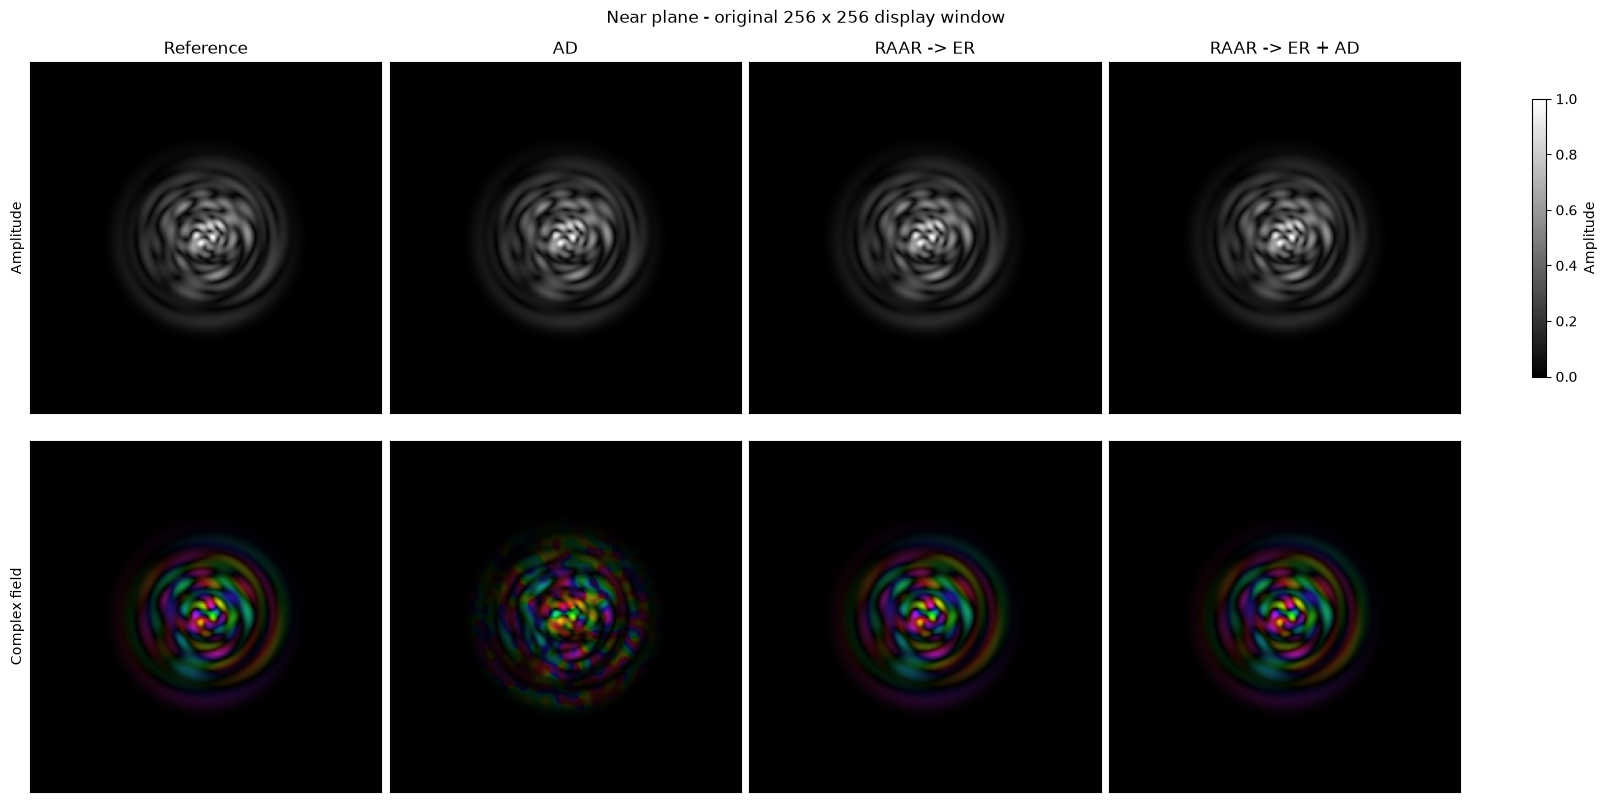

In [10]:
def show_amplitudes_and_fields(plane_fields, plane_name):
    reference_image = as_image(plane_fields["Reference"])
    amplitude_max = np.abs(reference_image).max()

    fig, axes = plt.subplots(
        2,
        len(plane_fields),
        figsize=(16, 8),
        constrained_layout=True,
    )

    for column, (name, estimate) in enumerate(plane_fields.items()):
        field_image = as_image(estimate)

        amplitude_plot = axes[0, column].imshow(
            np.abs(field_image),
            cmap="gray",
            vmin=0,
            vmax=amplitude_max,
        )

        colored_field = complex_to_hsv(
            field_image,
            rmin=0,
            rmax=amplitude_max,
        )

        axes[1, column].imshow(colored_field)
        axes[0, column].set_title(name)

        for row in range(2):
            axes[row, column].set_xticks([])
            axes[row, column].set_yticks([])

    axes[0, 0].set_ylabel("Amplitude")
    axes[1, 0].set_ylabel("Complex field")

    fig.colorbar(
        amplitude_plot,
        ax=axes[0].tolist(),
        label="Amplitude",
        shrink=0.75,
    )

    fig.suptitle(f"{plane_name} - original {height} x {width} display window")
    plt.show()


near_fields = {"Reference": reference, **aligned_results}

show_amplitudes_and_fields(near_fields, "Near plane")

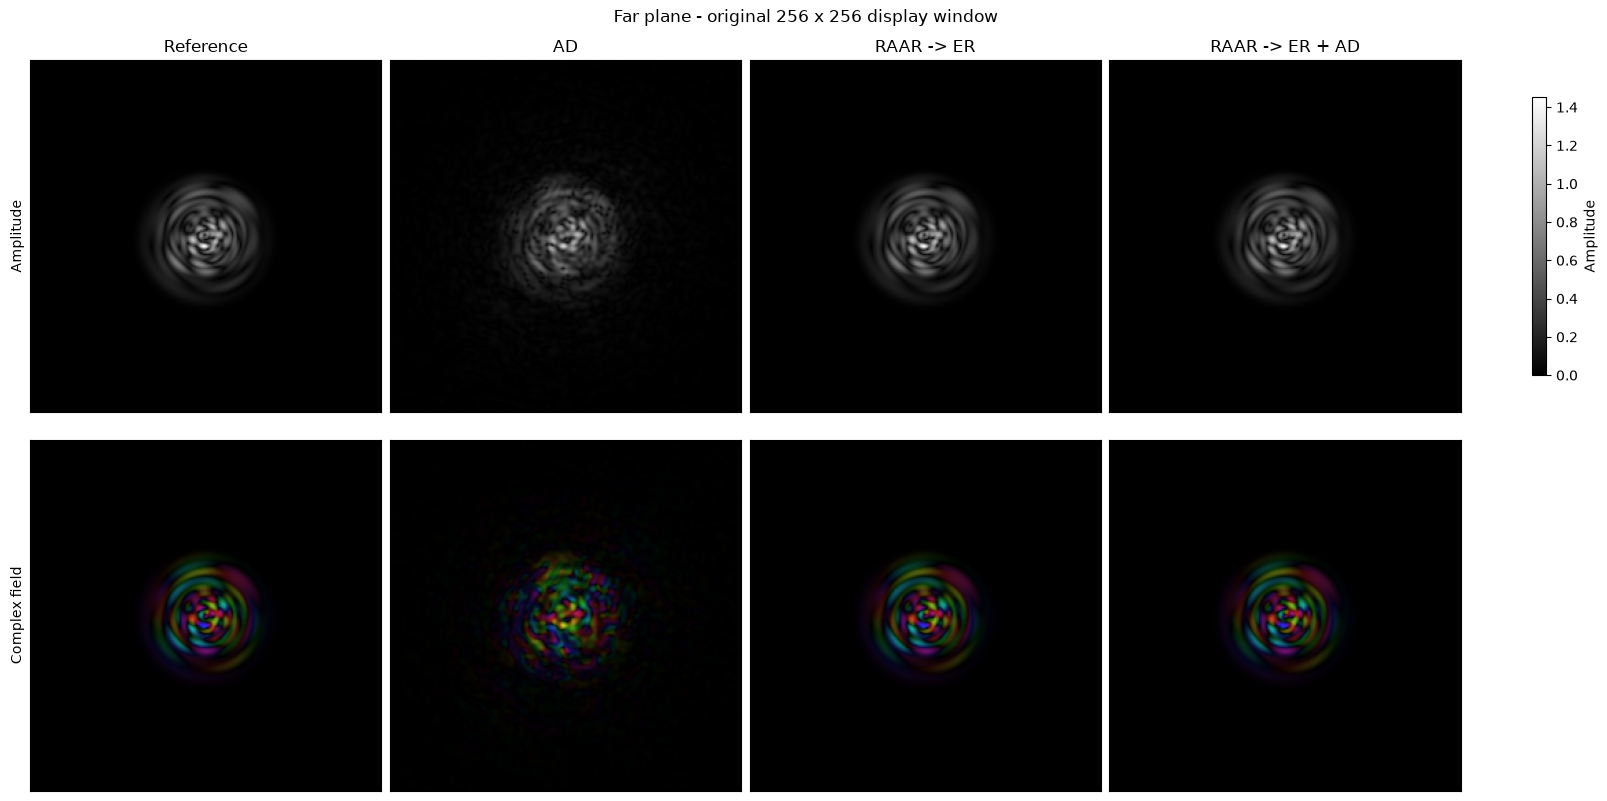

In [11]:
far_fields = {
    name: transforms.fourier_transform(estimate)
    for name, estimate in near_fields.items()
}

show_amplitudes_and_fields(far_fields, "Far plane")

## Compare phase errors

The wrapped phase error lies in [-pi, pi]. Zero means agreement after global-phase
alignment. This checks recovery against the known simulated reference; real
measurements usually have no reference phase.

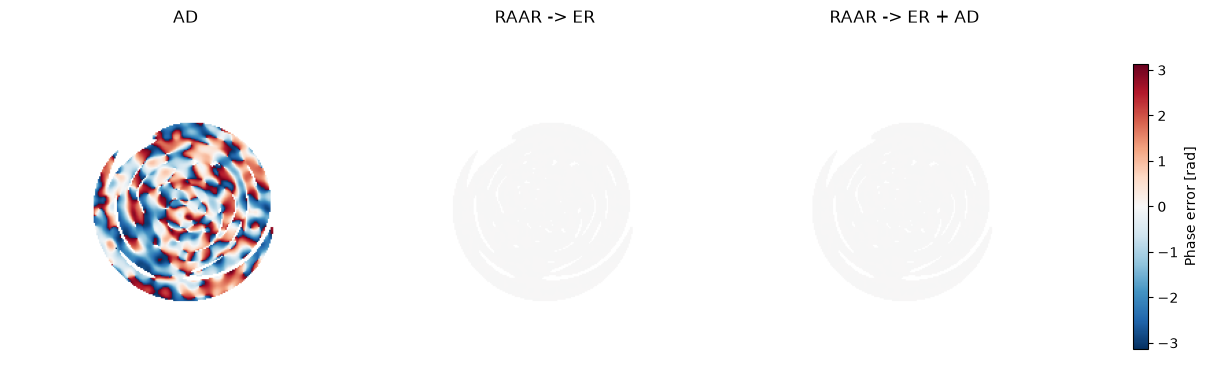

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4), constrained_layout=True)

for ax, (name, estimate) in zip(axes, aligned_results.items()):
    error = (estimate * reference.conj()).angle()
    error = torch.where(phase_mask, error, torch.nan)

    error_plot = ax.imshow(
        as_image(error),
        cmap="RdBu_r",
        vmin=-np.pi,
        vmax=np.pi,
    )

    ax.set_title(name)
    ax.set_axis_off()

fig.colorbar(error_plot, ax=axes.tolist(), label="Phase error [rad]", shrink=0.75)
plt.show()

## Compare measurement agreement and reference overlap

Lower far NMSE is better. Reference overlap ranges from 0 to 1, with 1 indicating
agreement up to global phase and scale. A small measurement residual alone does
not establish unique recovery.

The curves compare the two Adam runs using the same objective. The RAAR-ER
result is a horizontal baseline. Its staged convergence is shown separately
below, because raw RAAR states can retain feedback outside support.

Method                     Far NMSE      Overlap
------------------------------------------------
AD                          0.08236       0.0204
RAAR -> ER                 5.12e-14       1.0000
RAAR -> ER + AD           5.053e-14       1.0000


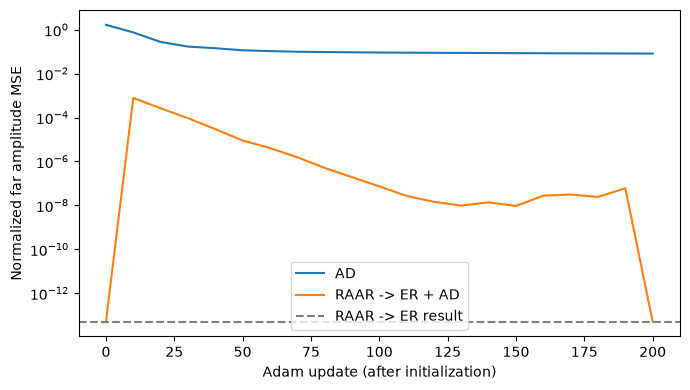

In [19]:
def far_nmse(estimate):
    predicted_far = transforms.fourier_transform(estimate)
    return metrics.normalized_mse(predicted_far, far).item()


print(f"{'Method':<22} {'Far NMSE':>12} {'Overlap':>12}")
print("-" * 48)

for name, estimate in results.items():
    residual = far_nmse(estimate)
    overlap = metrics.quality(estimate, reference, mask=support).item()

    print(f"{name:<22} {residual:12.4g} {overlap:12.4f}")


fig, ax = plt.subplots(figsize=(7, 4))

for name, history in [("AD", ad_history), ("RAAR -> ER + AD", hybrid_history)]:
    steps = history["iterations"].detach().cpu().numpy()
    losses = history["loss"][:, 0, 0].detach().cpu().numpy()

    ax.semilogy(steps, losses, label=name)

ax.axhline(
    far_nmse(projection_field),
    color="gray",
    linestyle="--",
    label="RAAR -> ER result",
)

ax.set_xlabel("Adam update (after initialization)")
ax.set_ylabel("Normalized far amplitude MSE")
ax.legend()

plt.tight_layout()
plt.show()

## Inspect the RAAR -> ER handoff

The vertical line marks the switch to ER. RAAR residuals describe raw iteration
states; the phase comparison above uses the final ER field.

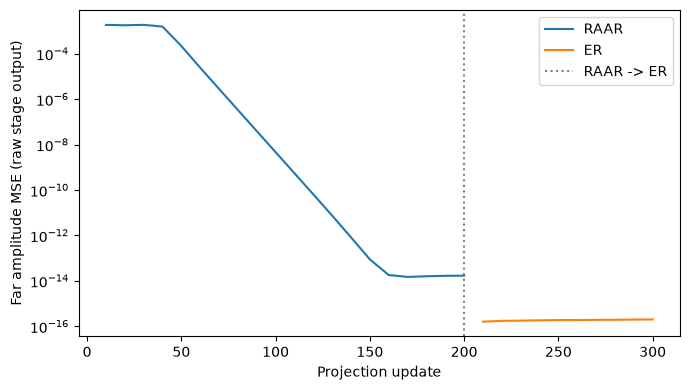

In [20]:
fig, ax = plt.subplots(figsize=(7, 4))

for name, history, offset in [
    ("RAAR", raar_history, 0),
    ("ER", er_history, raar_steps),
]:
    steps = history["iterations"].detach().cpu().numpy() + offset
    residuals = history["mse_fourier"][:, 0, 0].detach().cpu().numpy()

    ax.semilogy(steps, residuals, label=name)

ax.axvline(raar_steps, color="gray", linestyle=":", label="RAAR -> ER")
ax.set_xlabel("Projection update")
ax.set_ylabel("Far amplitude MSE (raw stage output)")
ax.legend()

plt.tight_layout()
plt.show()

For the saved CPU run, RAAR-ER recovers the reference up to global phase
(overlap approximately 1), whereas the single-start AD run stagnates. The phase-error maps
show this directly. AD refinement cannot meaningfully improve an already
converged solution. These results describe this simulated field and seed;
other data or starts may need more iterations or restarts.

## Optional: L-BFGS instead of Adam

Keep the same measurements, support, and random starting field; change only the
optimizer. L-BFGS uses a closure and can evaluate the objective several times per
outer update. Its 40 updates are therefore not the same budget as 40 Adam updates.

Set `init=projection_field` instead to refine the RAAR-ER solution with L-BFGS.

Far NMSE: 0.0740555077791214
Reference overlap: 0.04634515568614006
Objective evaluations: 283


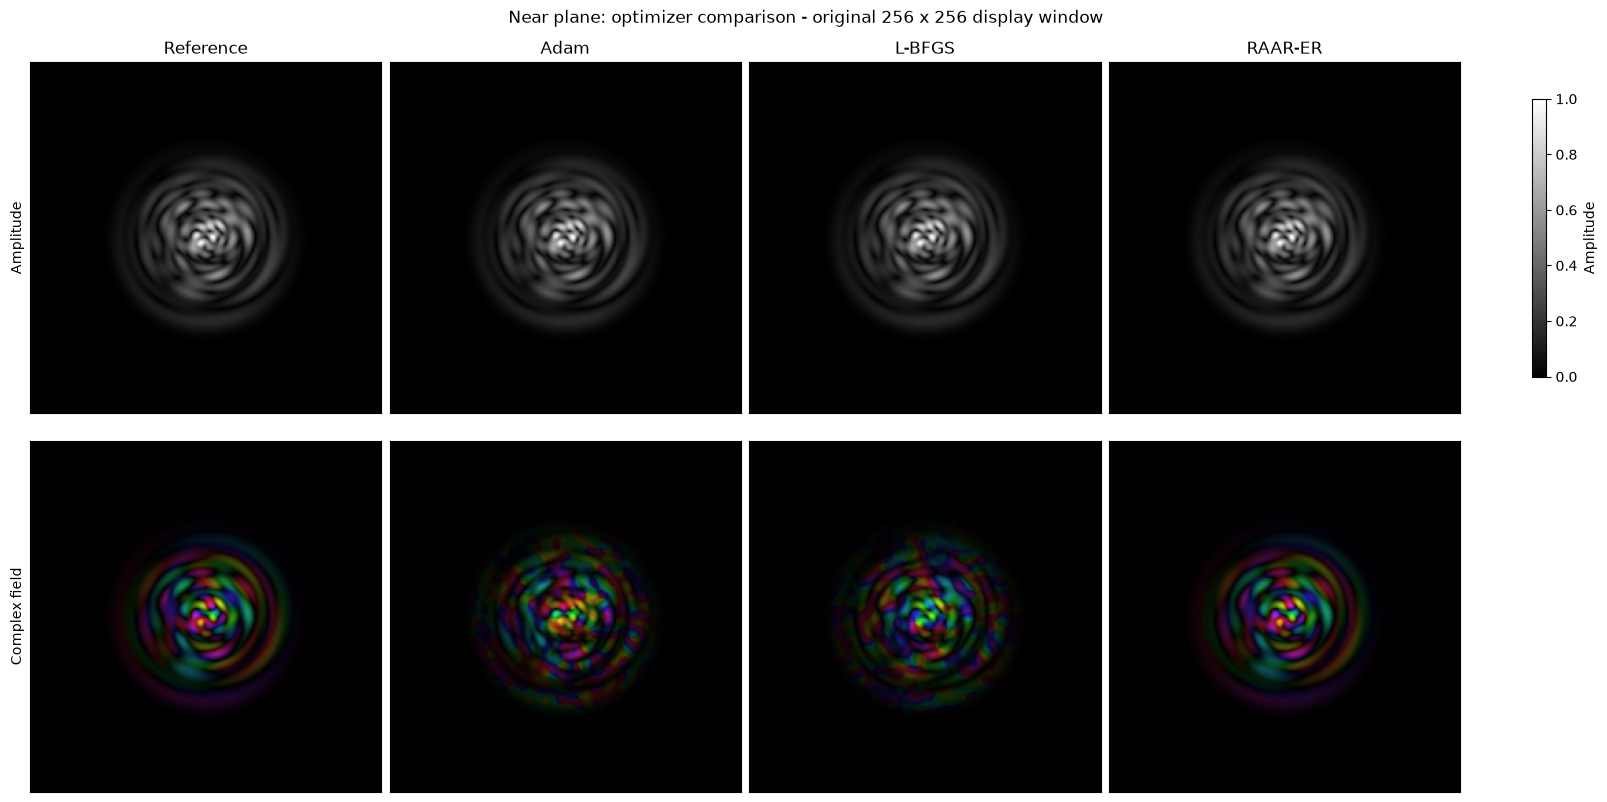

In [21]:
lbfgs_field, lbfgs_history = optimization.reconstruct(
    (near, far),
    support=support,
    init=start,
    optimizer_class=torch.optim.LBFGS,
    optimizer_kwargs={
        "max_iter": 5,
        "history_size": 10,
        "line_search_fn": "strong_wolfe",
    },
    max_iter=40,
    metric_every=5,
    return_best=True,
)

print("Far NMSE:", far_nmse(lbfgs_field))
print("Reference overlap:", metrics.quality(lbfgs_field, reference, mask=support).item())
print("Objective evaluations:", lbfgs_history["function_evaluations"])

show_amplitudes_and_fields(
    {
        "Reference": reference,
        "Adam": align_global_phase(ad_field),
        "L-BFGS": align_global_phase(lbfgs_field),
        "RAAR-ER": align_global_phase(projection_field),
    },
    "Near plane: optimizer comparison",
)

## Optional: other projection algorithms

Use the same random start and support to try three alternatives:

| Algorithm | Update |
| --- | --- |
| ER | Alternates far and near constraints directly. |
| HIO | Uses feedback outside support to help escape stagnation. |
| OSS | Adds staged smoothing outside support to HIO. |

For HIO and OSS, `enforce_magnitude=True` adds the measured near-amplitude
constraint; their default mode uses only support. OSS manages its smoothing
stages automatically. Each run below ends with the same 100 ER updates, so we
compare object fields after the same finishing step. Keep the final stage state
rather than selecting an intermediate raw state by Fourier MSE.

This small comparison illustrates the API; it does not establish an algorithm
ranking. Compare the colored fields with the reference as well as the residuals.

In [22]:
algorithms = {
    "ER": (retrieval.ER, {}),
    "HIO": (retrieval.HIO, {"beta": 0.9, "enforce_magnitude": True}),
    "OSS": (retrieval.OSS, {"beta": 0.9, "enforce_magnitude": True, "n_stages": 5}),
}

alternative_fields = {}

for name, (algorithm, options) in algorithms.items():
    candidate, _ = retrieval.run(
        (near, far),
        support=support,
        init=start,
        algorithm=algorithm,
        algorithm_kwargs=options,
        max_iter=raar_steps,
        metric_every=20,
    )

    finished, _ = retrieval.run(
        (near, far),
        support=support,
        init=candidate,
        algorithm=retrieval.ER,
        max_iter=er_steps,
        metric_every=20,
    )

    alternative_fields[name + " + ER finish"] = finished

Method                       Far NMSE      Overlap
RAAR + ER finish             5.12e-14       1.0000
ER + ER finish                0.06153       0.0323
HIO + ER finish               0.05428       0.0058
OSS + ER finish               0.05488       0.0076


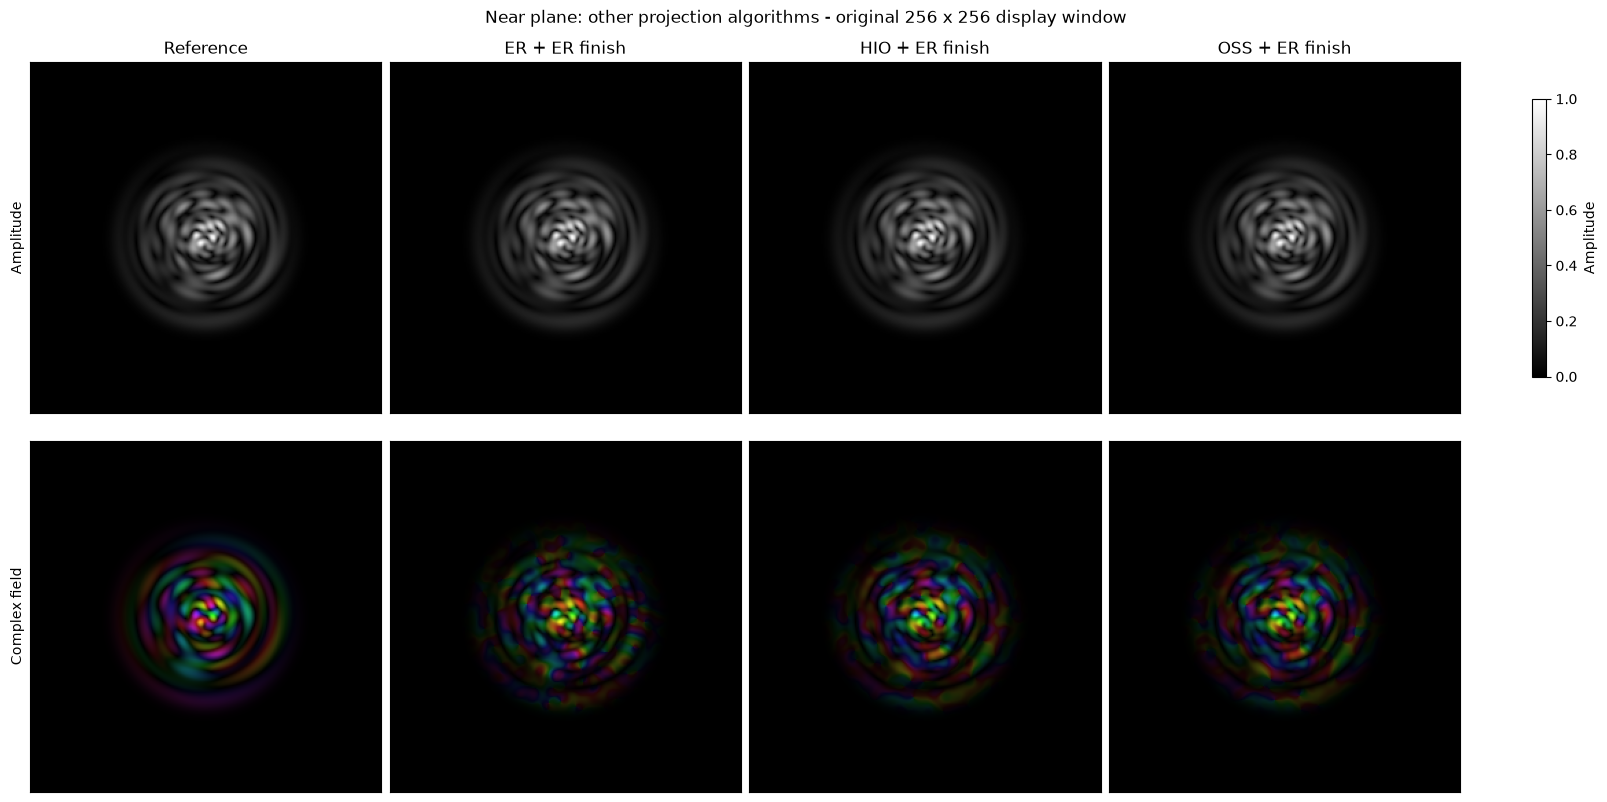

In [23]:
print(f"{'Method':<24} {'Far NMSE':>12} {'Overlap':>12}")

for name, estimate in {"RAAR + ER finish": projection_field, **alternative_fields}.items():
    residual = far_nmse(estimate)
    overlap = metrics.quality(estimate, reference, mask=support).item()

    print(f"{name:<24} {residual:12.4g} {overlap:12.4f}")


show_amplitudes_and_fields(
    {
        "Reference": reference,
        **{
            name: align_global_phase(estimate)
            for name, estimate in alternative_fields.items()
        },
    },
    "Near plane: other projection algorithms",
)

## Try another run

Change the random seed, support, iteration counts, or learning rate and rerun
from the starting-phase cell. A single random start can stagnate.

For multiple starts, use `retrieval.run_restarts`; for an automated RAAR-to-AD
pipeline, use `optimization.hybrid_reconstruct`. The explicit RAAR-ER sequence
above includes the ER finishing step. See the README for detector masks,
noisy count fitting, and custom propagation models.